In [1]:
from pathlib import Path
import json
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC, LinearSVC
from sklearn.metrics import(average_precision_score, roc_auc_score, f1_score, precision_score, recall_score,
                            precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict, learning_curve, train_test_split

os.environ["PYTHONWARNINGS"] = "ignore::FutureWarning"
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
DATA_DIR = Path("../data/processed")
TUNE_SAMPLE = 15000   #RBF SVM training scales roughly O(n^2), so the grid search runs on a stratified subsample of train
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

Loading Scaled Data and making sure everything matches 

In [2]:
X_train = pd.read_csv(DATA_DIR / "X_train_scaled.csv")
X_test = pd.read_csv(DATA_DIR / "X_test_scaled.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv")["hit"]
y_test = pd.read_csv(DATA_DIR / "y_test.csv")["hit"]
assert list(X_train.columns) == list(X_test.columns)
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
assert all(pd.api.types.is_numeric_dtype(X_train[c]) for c in X_train.columns)
print(f"Train {X_train.shape}, Test {X_test.shape}")
print(f"Hit rate: Train {y_train.mean():.1%}, Test {y_test.mean():.1%} (imbalance ratio in train {(y_train == 0).sum() / (y_train == 1).sum():.1f}:1)")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
#finds the threshold with the highest F1 on these scores (works for probabilities or SVM decision scores)
def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2*prec*rec/np.clip(prec + rec, 1e-12, None)
    i = np.nanargmax(f1[:-1])
    return f1[i], thr[i]

Train (45491, 25), Test (21760, 25)
Hit rate: Train 10.9%, Test 5.6% (imbalance ratio in train 8.2:1)


Baseline: Linear SVM with balanced class Weights + 5-Fold CV

In [4]:
baseline = LinearSVC(C=1.0, class_weight="balanced", dual=False, max_iter=5000)
oof = cross_val_predict(baseline, X_train, y_train, cv=skf, method="decision_function")
print(f"Linear SVM Cross Validation: PR-AUC {average_precision_score(y_train, oof):.3f}     ROC-AUC {roc_auc_score(y_train, oof):.3f}")

Linear SVM Cross Validation: PR-AUC 0.526     ROC-AUC 0.846


Hyperparameter tuning (RBF Kernel) Based on our results from logistic regression it is safe to assuke that non-linear kernel would be our next step. 

In [5]:
if len(X_train) > TUNE_SAMPLE:
    X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=TUNE_SAMPLE, stratify=y_train, random_state=RANDOM_STATE)
else:
    X_tune, y_tune = X_train, y_train
print(f"Tuning on {len(X_tune)} rows (hit rate {y_tune.mean():.1%})")

svc = SVC(kernel="rbf", class_weight="balanced", cache_size=1000)
parameter_grid = {"C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.03, 0.1]}
grid = GridSearchCV(svc, parameter_grid, scoring="average_precision", cv=skf, n_jobs=-1, return_train_score=True)
grid.fit(X_tune, y_tune)
cv = pd.DataFrame(grid.cv_results_)
print("Best parameter:", grid.best_params_, f"     CV PR-AUC (subsample) = {grid.best_score_:.4f}")
cv[["param_C", "param_gamma", "mean_train_score", "mean_test_score"]].sort_values("mean_test_score", ascending=False).head(8).round(4)

Tuning on 15000 rows (hit rate 10.9%)
Best parameter: {'C': 1, 'gamma': 0.01}      CV PR-AUC (subsample) = 0.5508


,param_C,param_gamma,mean_train_score,mean_test_score
5,1.0,0.01,0.5631,0.5508
1,0.1,0.01,0.5484,0.5455
2,0.1,0.03,0.5380,0.5270
9,10.0,0.01,0.5594,0.5251
6,1.0,0.03,0.5334,0.4991
13,100.0,0.01,0.5637,0.4855
10,10.0,0.03,0.5522,0.4579
0,0.1,scale,0.4981,0.4574


Checking for overfitting/underfitting with newly found best model
Learning model uses 15k tuning subsample in order to save time

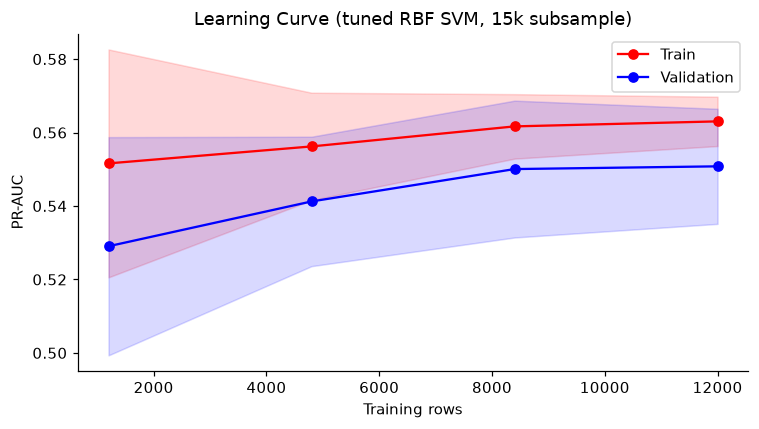

In [7]:
best_model = SVC(kernel="rbf", class_weight="balanced", cache_size=1000, **grid.best_params_)
sizes, tr_sc, va_sc = learning_curve(best_model, X_tune, y_tune, cv=skf, scoring="average_precision",
                                     train_sizes=np.linspace(0.1, 1.0, 4), n_jobs=-1, random_state=RANDOM_STATE, shuffle=True)
fig, ax = plt.subplots(figsize=(7, 4))
for sc, label, color in [(tr_sc, "Train", "red"), (va_sc, "Validation", "blue")]:
    ax.plot(sizes, sc.mean(axis=1), marker="o", color=color, label=label)
    ax.fill_between(sizes, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), color=color, alpha=.15)
ax.set_xlabel("Training rows")
ax.set_ylabel("PR-AUC")
ax.set_title("Learning Curve (tuned RBF SVM, 15k subsample)")
ax.legend()
plt.tight_layout()
plt.show()

In [8]:
oof = cross_val_predict(best_model, X_train, y_train, cv=skf, method="decision_function", n_jobs=-1)
cv_pr_auc_full = average_precision_score(y_train, oof)
f1_oof, THRESHOLD = best_f1_threshold(y_train, oof)
print(f"Full-train CV PR-AUC {cv_pr_auc_full:.3f}     ROC-AUC {roc_auc_score(y_train, oof):.3f}")
print(f"Optimal F1 threshold (decision score) from train CV:  {THRESHOLD:.3f}     (CV F1 = {f1_oof:.3f})")

Full-train CV PR-AUC 0.525     ROC-AUC 0.849
Optimal F1 threshold (decision score) from train CV:  0.843     (CV F1 = 0.529)


In [9]:
best_model.fit(X_train, y_train)
print(f"Support vectors: {best_model.n_support_.sum()} of {len(X_train)} training rows")
p_test = best_model.decision_function(X_test)
def report(y, p, thr):
    pred = (p >= thr).astype(int)
    return {"threshold": thr, "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
            "F1": f1_score(y, pred), "accuracy": (pred == y).mean()}

final = pd.DataFrame({
    "threshold 0 (default)": report(y_test, p_test, 0.0),
    f"threshold {THRESHOLD:.2f} (CV f1-optimal)": report(y_test, p_test, THRESHOLD)
}).T

print(f"Test PR-AUC {average_precision_score(y_test, p_test):.3f}     Test ROC-AUC {roc_auc_score(y_test, p_test):.3f}")
final.round(3)

Support vectors: 23493 of 45491 training rows
Test PR-AUC 0.341     Test ROC-AUC 0.850


,threshold,precision,recall,F1,accuracy
threshold 0 (default),0.000,0.220,0.726,0.337,0.840
threshold 0.84 (CV f1-optimal),0.843,0.357,0.551,0.433,0.919


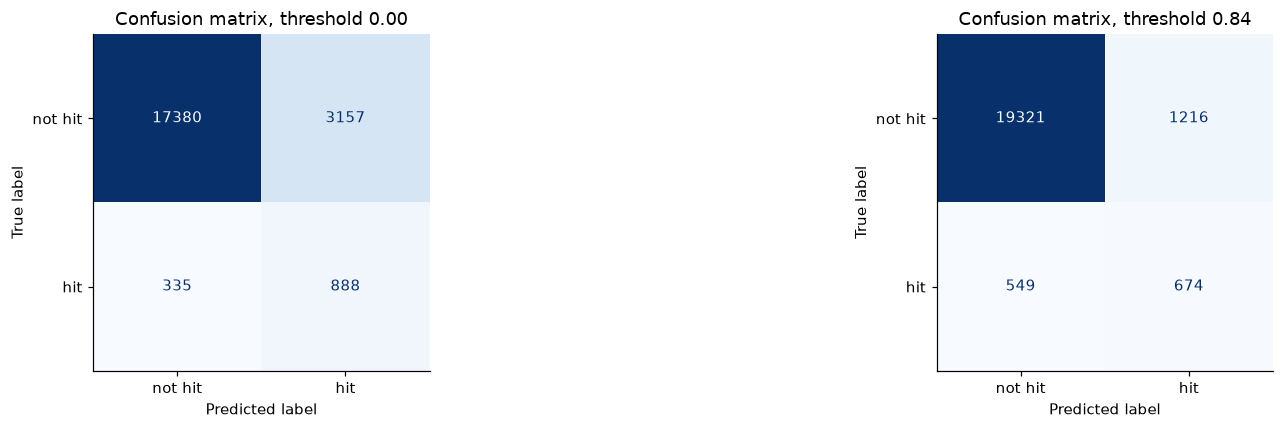

In [ ]:
fig, axes = plt.subplots(1,2, figsize=(18,4))
for ax, thr in zip(axes, [0.0, THRESHOLD]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p_test >= thr).astype(int)), display_labels=["not hit", "hit"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"Confusion matrix, threshold {thr:.2f}")
    ax.grid(False)
plt.tight_layout()
plt.show()

In [11]:
results = {
    "model": "svm_rbf",
    "preprocessing": "scaled data from preprocessing.ipynb, class_weight=balanced",
    "score_type": "decision_function (thresholds are margin distances, not probabilities)",
    "best_params": {k: v for k, v in grid.best_params_.items()},
    "tune_sample_rows": int(len(X_tune)),
    "cv_pr_auc_tune_sample": float(grid.best_score_),
    "cv_pr_auc": float(cv_pr_auc_full),
    "test_pr_auc": float(average_precision_score(y_test, p_test)),
    "test_roc_auc": float(roc_auc_score(y_test, p_test)),
    "test_random_guesser_pr_auc": float(y_test.mean()), #what a random guesser would get
    "threshold_cv_f1_optimal": float(THRESHOLD),
    "test_at_0": {k: float(v) for k, v in report(y_test, p_test, 0.0).items()},
    "test_at_cv_threshold": {k: float(v) for k, v in report(y_test, p_test, THRESHOLD).items()},
}
with open(DATA_DIR / "svm_results.json", "w") as f:
    json.dump(results, f, indent=1, default=str)
print(json.dumps(results, indent=1, default=str))

{
 "model": "svm_rbf",
 "preprocessing": "scaled data from preprocessing.ipynb, class_weight=balanced",
 "score_type": "decision_function (thresholds are margin distances, not probabilities)",
 "best_params": {
  "C": 1,
  "gamma": 0.01
 },
 "tune_sample_rows": 15000,
 "cv_pr_auc_tune_sample": 0.5507974928998545,
 "cv_pr_auc": 0.525485568767494,
 "test_pr_auc": 0.341265802738516,
 "test_roc_auc": 0.8501131575497165,
 "test_random_guesser_pr_auc": 0.05620404411764706,
 "threshold_cv_f1_optimal": 0.8433154515819941,
 "test_at_0": {
  "threshold": 0.0,
  "precision": 0.21953028430160693,
  "recall": 0.7260834014717906,
  "F1": 0.33712984054669703,
  "accuracy": 0.8395220588235294
 },
 "test_at_cv_threshold": {
  "threshold": 0.8433154515819941,
  "precision": 0.3566137566137566,
  "recall": 0.5511038430089943,
  "F1": 0.43302280758111145,
  "accuracy": 0.9188878676470589
 }
}
